In [1]:
# Preparar un entorno reproducible y ubicar los archivos sin pedir rutas interactivas.
from pathlib import Path
import json, sys, importlib.metadata, itertools, hashlib, csv
# Usar las dependencias locales si estan disponibles.
for carpeta in (Path.cwd() / "analisis" / ".dependencias",
                Path.cwd().parent / "analisis" / ".dependencias"):
    if carpeta.is_dir():
        sys.path.insert(0, str(carpeta))
        break
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
SEED = 42
rng = np.random.default_rng(SEED)
NOMBRES = {'costos': 'Viajes con Costos V2',
           'tiempos': 'Tiempos Viajes Foraneos',
           'ciclos': 'Detalle Ciclos de Viajes Despachados'}
bases = [Path.cwd()/'data', Path.cwd()/'notebook_entrega1'/'data',
         Path.cwd(), Path.cwd()/'upload', Path.cwd()/'datos',
         Path.cwd().parent/'upload', Path.cwd().parents[1]/'upload']
DATA = None
for carpeta in bases:
    for extension in ('.xlsx', '.csv'):
        candidatos = {k: nombre + extension for k, nombre in NOMBRES.items()}
        if all((carpeta / nombre).is_file() for nombre in candidatos.values()):
            DATA, ARCHIVOS = carpeta, candidatos
            break
    if DATA is not None:
        break
if DATA is None:
    raise FileNotFoundError('No se encontraron los tres archivos originales Excel o CSV en data/, notebook_entrega1/data/, upload/ o datos/.')
OUT = DATA.parent/'resultados_ternium'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'figure.dpi':130,'savefig.dpi':200})
def mostrar(df): print(df.to_string(index=False))
def figura(fig, nombre):
    fig.tight_layout(); fig.savefig(OUT/nombre,bbox_inches='tight'); plt.show(); plt.close(fig)
def tabla(df,nombre):
    df.to_csv(OUT/nombre,index=False,encoding='utf-8-sig'); mostrar(df)
def ptexto(p): return '< 1e-300' if p == 0 else f'{p:.3g}'
print('Python:',sys.version.split()[0])
versiones={n:importlib.metadata.version(n) for n in ['pandas','numpy','scipy','scikit-learn','matplotlib']}
print('Versiones:',versiones)
# Detectar el separador y el formato numerico de cada exportacion CSV.
def leer_archivo(archivo, tipo):
    if archivo.suffix.lower() == '.xlsx':
        df = pd.read_excel(archivo, engine='openpyxl')
    else:
        with archivo.open(encoding='utf-8-sig', newline='') as entrada:
            encabezado = entrada.readline()
        separador = csv.Sniffer().sniff(encabezado, delimiters=',;\t').delimiter
        formato = {}
        if tipo == 'costos':
            formato = (dict(thousands='.', decimal=',') if separador == ';'
                       else dict(thousands=',', decimal='.'))
        df = pd.read_csv(archivo, sep=separador, encoding='utf-8-sig',
                         low_memory=False, **formato)
    df.columns = df.columns.astype(str).str.replace('\ufeff', '', regex=False).str.strip()
    requeridas = {
        'costos': ['Viaje', 'Peso Total', 'Monto total', '#Remitos', 'F.Salida', 'F.CargaP'],
        'tiempos': ['ID_VIAJE_NCA', 'COD_PLANTA_ORIGEN', 'D_REGION', 'ZONA_LOCALIDAD'],
        'ciclos': ['ID Viaje']
    }
    faltantes = [col for col in requeridas[tipo] if col not in df.columns]
    if faltantes:
        raise ValueError(f'{archivo}: faltan columnas {faltantes}. Encabezados leidos: {list(df.columns)}')
    return df

datos = {k: leer_archivo(DATA / nombre, k) for k, nombre in ARCHIVOS.items()}
c,t,d=datos['costos'],datos['tiempos'],datos['ciclos']
for col in ['Peso Total', 'Monto total', '#Remitos']:
    c[col] = pd.to_numeric(c[col], errors='raise')
for col in ['F.Salida','F.CargaP']:
    if not pd.api.types.is_datetime64_any_dtype(c[col]):
        c[col] = pd.to_datetime(c[col], format='mixed', dayfirst=True, errors='raise')
print('Datos cargados desde:', DATA.resolve())
print('Archivos:', ARCHIVOS)
resumen={'versiones':versiones,'semilla':SEED,
         'archivos_sha256':{n:hashlib.sha256((DATA/n).read_bytes()).hexdigest() for n in ARCHIVOS.values()}}

Python: 3.13.14
Versiones: {'pandas': '3.0.6', 'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
Datos cargados desde: C:\Users\Ian\Desktop\Ternium_reto\notebook_entrega1\data
Archivos: {'costos': 'Viajes con Costos V2.xlsx', 'tiempos': 'Tiempos Viajes Foraneos.xlsx', 'ciclos': 'Detalle Ciclos de Viajes Despachados.xlsx'}


## Auditoría del contrafactual
Pregunta: ¿se registra el costo y la disponibilidad de cada camión elegible que no se usó?

La evidencia se obtiene del inventario completo de columnas y de la estructura de los registros. `Monto total` está ligado al `Viaje` realizado; no existe una lista de alternativas para ese mismo viaje con tarifas y disponibilidad a la hora de decidir. `FAMILIA_CAMION_DESC` y `Desc TpoTrn` describen equipos observados, no todos los candidatos.

**Conclusión de alcance:** el contrafactual no está registrado explícitamente en los tres archivos recibidos. Esto no demuestra que Ternium carezca de esos registros en otros sistemas. No se recibió el listado formal de datos solicitados; no podemos auditar pedido versus recepción ni afirmar que Ternium rechazó proporcionarlos.

In [2]:
# Documentar TODAS las columnas; evitar deducir ausencias a partir de unas pocas muestras.
inventario=pd.DataFrame([{'Archivo':ARCHIVOS[k],'Columna':col,'Tipo':str(df[col].dtype),
                        'Faltantes':int(df[col].isna().sum()),'Valores distintos':int(df[col].nunique())}
                       for k,df in datos.items() for col in df.columns])
tabla(inventario,'inventario_columnas.csv')
auditoria=pd.DataFrame([
 ['Camión usado','Sí','Desc TpoTrn / FAMILIA_CAMION_DESC'],
 ['Costo observado','Sí','Monto total; Moneda = MXN'],
 ['Peso transportado','Sí, unidad pendiente','Peso Total'],
 ['Tarifa del camión no usado','No explícita','Sin tabla de alternativas por decisión'],
 ['Disponibilidad al asignar','No explícita','Sin estado de flota a la hora de decisión'],
 ['Capacidad por equipo y peso por eje','No explícita','Los nombres de ejes no dan límites de carga'],
 ['Volumen, dimensiones y producto','No explícitos','Sin medidas o catálogo de productos'],
 ['Ventana de entrega acordada','No explícita','ETA y ETA_FLEX requieren diccionario'],
 ['Pedido dividido o consolidado','No reconstruible','Hay #Remitos, pero no IDs de pedido por remito']
],columns=['Dato necesario','Resultado','Evidencia'])
tabla(auditoria,'auditoria_contrafactual.csv')
print('Monedas observadas:',c.Moneda.value_counts().to_dict())
print('Estados de tiempos:',t.ESTADO.value_counts().to_dict())
print('Categorías de ciclos:',d['Cant. Ciclos'].value_counts().to_dict())
resumen['auditoria']=auditoria.to_dict('records')

                                  Archivo                  Columna           Tipo  Faltantes  Valores distintos
                Viajes con Costos V2.xlsx                    Viaje          int64          0              91619
                Viajes con Costos V2.xlsx                  Permiso          int64          0              90542
                Viajes con Costos V2.xlsx            Planta Origen            str          0                 49
                Viajes con Costos V2.xlsx            Desc Org. Apt            str          0                 50
                Viajes con Costos V2.xlsx                   Nombre            str          0                164
                Viajes con Costos V2.xlsx               TpoTrn.APT          int64          0                 23
                Viajes con Costos V2.xlsx              Desc TpoTrn         object          0                  8
                Viajes con Costos V2.xlsx                   TpoSrv            str       5369            

## Fenómeno 1 · La unidad de observación
Pregunta guía: ¿una fila representa un viaje completo o un registro asociado a él?

Se cuentan filas, IDs distintos, IDs repetidos y duplicados exactos en **cada archivo**. Una repetición de ID no es por sí misma un error: puede representar destinos, actualizaciones, documentos o eventos. Se inspeccionan diferencias de columnas sin mostrar datos personales.

Para las estadísticas adoptamos una unidad operativa conservadora: un viaje con un solo registro de costos y una sola combinación inequívoca de origen, destino, camión y fechas en tiempos. Colapsamos únicamente proyecciones idénticas de tiempos; excluimos los IDs con combinaciones distintas. No agregamos costos repetidos ni asignamos a mano un destino. Esta selección reduce cobertura y sus resultados no representan automáticamente toda la flota.

Archivo  Filas  IDs únicos  IDs con varias filas  Filas adicionales por ID  Duplicados exactos
 costos  91772       91619                   145                       153                   0
tiempos 105449       93239                 10296                     12210                   7
 ciclos   7476        6051                  1232                      1425                   0
Archivo             Columna  IDs repetidos con diferencias
 costos             Permiso                            140
 costos       Planta Origen                            134
 costos       Desc Org. Apt                            134
 costos          TpoTrn.APT                              1
 costos              TpoSrv                              5
 costos            F.Salida                             57
 costos            H.Salida                            140
 costos            #Remitos                             36
 costos          Peso Total                              5
 costos            Shp.Cost   

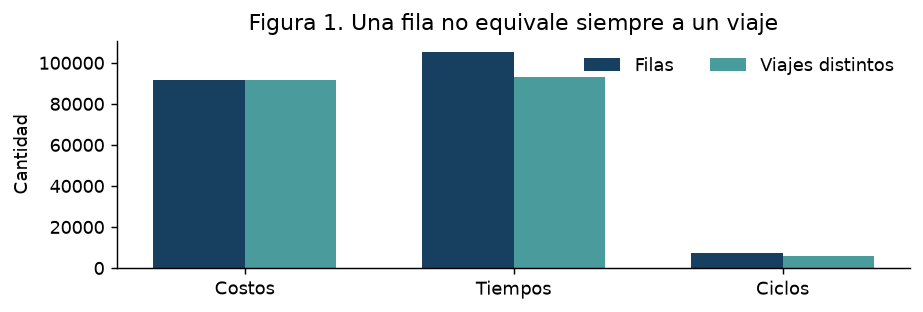

                                  Paso  Cantidad
               Filas costos originales     91772
         Viajes costos sin ID repetido     91474
   Viajes tiempos con proyección única     82954
               Viajes unidos uno a uno     76071
                  Origen inconsistente         1
Base final positiva y origen coherente     76070
     Etapa  Faltantes  Negativos  Mediana no negativa
  Espera_h       5844          2             0.433333
  Planta_h       5844         27             3.266667
Traslado_h      21083          2            26.964722


In [3]:
# Medir repetición y verificar qué campos cambian dentro del mismo identificador.
ids={'costos':'Viaje','tiempos':'ID_VIAJE_NCA','ciclos':'ID Viaje'}
for k,df in datos.items():
    df[ids[k]]=df[ids[k]].astype('string').str.replace(r'\.0$','',regex=True).str.strip()
filas=[]; conflictos=[]
for k,df in datos.items():
    conteos=df[ids[k]].value_counts()
    filas.append({'Archivo':k,'Filas':len(df),'IDs únicos':df[ids[k]].nunique(),
                  'IDs con varias filas':int((conteos>1).sum()),
                  'Filas adicionales por ID':len(df)-df[ids[k]].nunique(),
                  'Duplicados exactos':int(df.duplicated().sum())})
    multi=df[df[ids[k]].duplicated(False)]
    for col in df.columns:
        if col not in [ids[k],'Chofer','Placas tract','Placas plat']:
            n=int((multi.groupby(ids[k])[col].nunique(dropna=False)>1).sum())
            if n: conflictos.append({'Archivo':k,'Columna':col,'IDs repetidos con diferencias':n})
unidades=pd.DataFrame(filas);tabla(unidades,'unidad_observacion.csv')
tabla(pd.DataFrame(conflictos),'diferencias_por_id.csv')
fig,ax=plt.subplots(figsize=(7.2,2.5))
x=np.arange(3); ax.bar(x-.17,unidades.Filas,width=.34,label='Filas',color='#173F5F')
ax.bar(x+.17,unidades['IDs únicos'],width=.34,label='Viajes distintos',color='#4A9B9C')
ax.set_xticks(x,['Costos','Tiempos','Ciclos']);ax.set_ylabel('Cantidad');ax.set_title('Figura 1. Una fila no equivale siempre a un viaje')
ax.legend(frameon=False,ncol=2);ax.ticklabel_format(axis='y',style='plain')
figura(fig,'figura_1_unidades.png')
cc=c.loc[~c.Viaje.duplicated(False)].copy()
campos_t=['ID_VIAJE_NCA','COD_PLANTA_ORIGEN','D_REGION','ZONA_LOCALIDAD','GEOCERCA_ID',
          'TIPO_DESPACHO','FAMILIA_CAMION_DESC','FECHA_PRESENTACION','FECHA_INGRESO','FECHA_EGRESO',
          'FECHA_LLEGADA_GEO_CERCA']
tt=t[campos_t].drop_duplicates().copy()
tt=tt.loc[~tt.ID_VIAJE_NCA.duplicated(False)].copy()
b=cc.merge(tt,left_on='Viaje',right_on='ID_VIAJE_NCA',how='inner',validate='one_to_one')
origen_ok=b['Planta Origen'].astype('string').eq(b.COD_PLANTA_ORIGEN.astype('string'))
flujo={'Filas costos originales':len(c),'Viajes costos sin ID repetido':len(cc),
       'Viajes tiempos con proyección única':len(tt),'Viajes unidos uno a uno':len(b),
       'Origen inconsistente':int((~origen_ok).sum())}
b=b.loc[origen_ok].copy()
for col in ['Peso Total','Monto total','#Remitos']:
    b[col]=pd.to_numeric(b[col],errors='coerce')
validos=(b['Peso Total']>0)&(b['Monto total']>0)&(b['#Remitos']>0)
b=b.loc[validos].copy()
b['Ruta']=b['Planta Origen'].astype('string')+' → '+b.D_REGION.astype('string')+' / '+b.ZONA_LOCALIDAD.astype('string')
b['Fecha']=pd.to_datetime(b['F.Salida'],errors='coerce')
for col in ['FECHA_PRESENTACION','FECHA_INGRESO','FECHA_EGRESO','FECHA_LLEGADA_GEO_CERCA']:
    b[col]=pd.to_datetime(b[col],format='%d/%m/%Y %H:%M:%S',errors='coerce')
pares={'Espera_h':('FECHA_PRESENTACION','FECHA_INGRESO'),
       'Planta_h':('FECHA_INGRESO','FECHA_EGRESO'),
       'Traslado_h':('FECHA_EGRESO','FECHA_LLEGADA_GEO_CERCA')}
calidad=[]
for nombre,(ini,fin) in pares.items():
    h=(b[fin]-b[ini]).dt.total_seconds()/3600
    calidad.append({'Etapa':nombre,'Faltantes':int(h.isna().sum()),'Negativos':int((h<0).sum()),
                    'Mediana no negativa':float(h[h>=0].median())})
    b[nombre]=h.mask(h<0) # Una duración negativa es no interpretable; no se reemplaza por cero.
flujo['Base final positiva y origen coherente']=len(b)
tabla(pd.DataFrame(list(flujo.items()),columns=['Paso','Cantidad']),'flujo_muestra.csv')
tabla(pd.DataFrame(calidad),'calidad_tiempos.csv')
resumen.update({'unidades':unidades.to_dict('records'),'flujo':flujo,'calidad_tiempos':calidad,
 'coincidencias_costos_tiempos':len(set(c.Viaje)&set(t.ID_VIAJE_NCA)),
 'coincidencias_tres':len(set(c.Viaje)&set(t.ID_VIAJE_NCA)&set(d['ID Viaje']))})
assert b.Viaje.is_unique

**Lectura de figura 1:** tiempos tiene 105,449 filas para 93,239 IDs; ciclos 7,476 para 6,051; costos 91,772 para 91,619. Cambios de destino/geocerca y planta muestran que no son meros duplicados. La selección produce 76,070 viajes con unión uno a uno; es conservadora y pierde cobertura.

## Análisis 1 · Distribuciones y anomalías
Pregunta: ¿los valores extremos y la falta de fechas alteran la historia que contaríamos con un promedio?

Se describen peso y costo en toda la tabla de costos, sin borrar extremos. Se reportan mediana, percentiles, media, desviación estándar, asimetría y proporción fuera de la regla de Tukey (1.5 veces el rango intercuartílico). Esa regla marca observaciones para revisión: no certifica errores. El umbral de peso >100,000 se usa únicamente como señal de auditoría, no como límite legal. La unidad del peso sigue pendiente; no presentamos toneladas ni utilización.

Las figuras usan eje logarítmico para hacer visibles tanto la concentración como la cola, y conservan los valores originales. La log-transformación para PCA no convierte los datos en normales ni corrige errores de captura.

   Variable     n        Media  Mediana  Desv estándar      P95      P99     Máximo  Asimetría  Fuera de Tukey %
 Peso Total 91772 30363.834732 29381.50  278179.565111 36612.45 43115.35 62058000.0 171.746718          5.174781
Monto total 91772 27404.851493 21738.09   20914.330235 70182.00 97190.70   185000.0   1.627047          3.495620


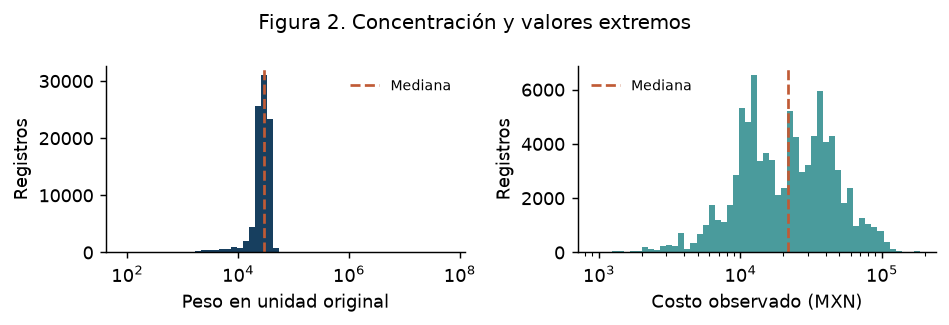

   Viaje Desc TpoTrn  Peso Total  Monto total
73838769      2_EJES      302000     22000.00
73882999      2_EJES      322000     22000.00
73884302      2_EJES     3176000     22000.00
73900374      2_EJES    62058000     22000.00
73910245      2_EJES     1309000     22000.00
73950296      2_EJES      302000     22000.00
73945478      2_EJES      334000     22000.00
73944058      2_EJES      322000     22000.00
73954841      2_EJES      709000     11000.00
73845828      2_EJES     1306000     36634.96
73949260      2_EJES    13700000      7816.91
73955369      2_EJES      754000     11000.00
73992588      2_EJES      303000     22000.00
73992873      2_EJES      575000     22000.00
73852932      2_EJES    13885000     22000.00
74101573      2_EJES      328000     11000.00
74160647   CAMIONETA      120000      3090.00
74199117   CAMIONETA      134000      1545.00
74273636      2_EJES      235000     36634.96
74298398      2_EJES     9243000     36634.96
74293224      2_EJES     2515000  

In [4]:
# Comparar centro y cola antes de proponer transformaciones.
distrib=[]
for col in ['Peso Total','Monto total']:
    s=pd.to_numeric(c[col],errors='coerce').dropna()
    q1,q3=s.quantile([.25,.75]);iqr=q3-q1
    distrib.append({'Variable':col,'n':len(s),'Media':s.mean(),'Mediana':s.median(),
     'Desv estándar':s.std(),'P95':s.quantile(.95),'P99':s.quantile(.99),'Máximo':s.max(),
     'Asimetría':stats.skew(s,bias=False),'Fuera de Tukey %':100*((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).mean()})
distrib=pd.DataFrame(distrib);tabla(distrib,'distribuciones.csv')
fig,axs=plt.subplots(1,2,figsize=(7.4,2.5))
for ax,col,color in zip(axs,['Peso Total','Monto total'],['#173F5F','#4A9B9C']):
    s=pd.to_numeric(c[col],errors='coerce');s=s[s>0]
    ax.hist(s,bins=np.geomspace(s.min(),s.max(),55),color=color)
    ax.set_xscale('log');ax.axvline(s.median(),color='#C05B36',ls='--',label='Mediana')
    ax.set_xlabel('Peso en unidad original' if col=='Peso Total' else 'Costo observado (MXN)')
    ax.set_ylabel('Registros');ax.legend(frameon=False,fontsize=8)
fig.suptitle('Figura 2. Concentración y valores extremos',fontsize=11)
figura(fig,'figura_2_distribuciones.png')
extremos=c.loc[pd.to_numeric(c['Peso Total'],errors='coerce')>100000,['Viaje','Desc TpoTrn','Peso Total','Monto total']]
tabla(extremos,'pesos_para_validar.csv')
resumen['distribuciones']=distrib.to_dict('records');resumen['pesos_mayores_100000']=len(extremos)
resumen['faltante_llegada_original']=int(t.FECHA_LLEGADA_GEO_CERCA.isna().sum())

**Lectura de figura 2:** peso mediano 29,381.5 y máximo 62,058,000; 44 valores superan 100,000 y requieren confirmación de unidad y captura. Costo mediano MXN 21,738 frente a media 27,404.85: la cola derecha eleva la media. Escala logarítmica expone concentración y extremos, sin certificar errores.

## Fenómeno 2 · El sesgo de lo que se observa
Pregunta guía: ¿la mezcla de tipos de camión es similar entre plantas, o la asignación histórica ya filtra lo que podemos comparar?

Analizamos plantas y tipos con al menos 500 viajes en la base conservadora; documentamos la cobertura y verificamos frecuencias esperadas antes de interpretar chi-cuadrada. Cramér V acompaña al p-value para medir magnitud. El p-value de chi-cuadrada presupone independencia de observaciones, que viajes repetidos de un mismo proveedor/ruta pueden incumplir; se interpreta como evidencia exploratoria bajo ese supuesto. Una dependencia no demuestra una mala asignación ni identifica su causa. El mapa resume porcentajes dentro de cada planta y no expresa utilización.

Planta Origen  2_EJES  3_EJES  CAMIONETA  MENORES  PORTACINTAS
         BSLO       0     649          0        0           41
         BSR2     177     396          0        0            0
          CHU     943    6834          0        0          649
         CSCA    4840     157          1        0            3
         CSIA      69    1909          0        0          147
         CSIS     378     520          0        0           59
          GDL      40       0        397      612            0
          GUE    1549    6651          0        0          231
          JUV    2275    5140          0        0          190
          LAP    3508    4402          0        0            5
          LEO      10      67        203      325            0
          LPU     757    7981          0        0            0
          MEX    1097      50         35      216            0
          MVA       0    1112          0        0            3
          PSQ    2463   11922          0        0      

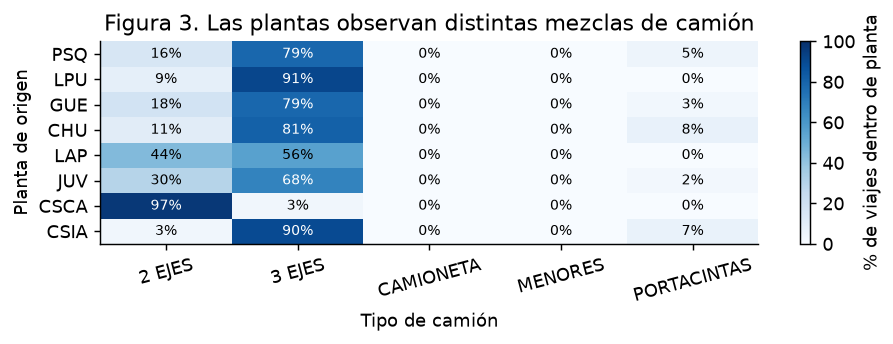

In [5]:
# Medir la estructura de selección histórica y no confundir presencia con elegibilidad.
plantas=b['Planta Origen'].value_counts();tipos=b['Desc TpoTrn'].value_counts()
sesgo=b[b['Planta Origen'].isin(plantas[plantas>=500].index)&b['Desc TpoTrn'].isin(tipos[tipos>=500].index)]
ct=pd.crosstab(sesgo['Planta Origen'],sesgo['Desc TpoTrn'])
chi,pchi,dof,esperados=stats.chi2_contingency(ct,correction=False)
v=np.sqrt(chi/(ct.to_numpy().sum()*min(ct.shape[0]-1,ct.shape[1]-1)))
por=ct.div(ct.sum(axis=1),axis=0)*100
tabla(ct.reset_index(),'planta_tipo_conteos.csv')
tabla(por.reset_index(),'planta_tipo_porcentajes.csv')
print('Chi2:',chi,'gl:',dof,'p:',ptexto(pchi),'Cramér V:',v,'mínimo esperado:',esperados.min())
resumen['sesgo']={'n':len(sesgo),'cobertura_base':len(sesgo)/len(b),'chi2':chi,'gl':dof,
 'p':float(pchi),'cramer_v':v,'min_esperado':float(esperados.min()),'plantas':len(ct),'tipos':len(ct.columns)}
top=b['Planta Origen'].value_counts().head(8).index
vista=por.loc[[i for i in top if i in por.index]]
fig,ax=plt.subplots(figsize=(7.3,2.75))
im=ax.imshow(vista,cmap='Blues',vmin=0,vmax=100,aspect='auto')
ax.set_xticks(range(len(vista.columns)),[str(i).replace('_',' ') for i in vista.columns],rotation=15)
ax.set_yticks(range(len(vista)),vista.index);ax.set_xlabel('Tipo de camión');ax.set_ylabel('Planta de origen')
for i in range(len(vista)):
    for j in range(len(vista.columns)):
        valor=vista.iloc[i,j];ax.text(j,i,f'{valor:.0f}%',ha='center',va='center',fontsize=8,color='white' if valor>60 else 'black')
fig.colorbar(im,ax=ax,label='% de viajes dentro de planta')
ax.set_title('Figura 3. Las plantas observan distintas mezclas de camión')
figura(fig,'figura_3_sesgo.png')

**Lectura de figura 3:** la mezcla de camiones cambia por planta. Chi2=82,775.21, gl=64, p<1e-300, V=0.535 y mínimo esperado=6.67 en 72,219 viajes. La asociación describe la selección observada, no la disponibilidad del camión descartado ni la causa de la asignación. La figura muestra ocho plantas; la prueba usa 17.

## Análisis 2 · Relaciones y validación estadística
Pregunta: ¿las asociaciones con el costo persisten al comparar viajes dentro de una misma ruta?

Usamos Spearman por la asimetría y los extremos. Tres relaciones predefinidas: peso–costo, remitos–costo y traslado–costo. Además de rho y n se reportan p-values bilaterales y corrección Holm de esas tres pruebas. Los p-values asintóticos presuponen independencia; se agrega una sensibilidad por ruta con una mediana por ruta (al menos 30 viajes). La independencia entre rutas también es una aproximación.

Para peso–costo calculamos una asociación dentro de ruta, restando a los rangos su media por ruta. Un contraste por permutación mezcla los costos SOLO dentro de cada ruta, con semilla fija y 999 repeticiones, en rutas con al menos 30 viajes. Es un contraste exploratorio que presupone intercambiabilidad dentro de ruta y no controla producto, contrato, fecha o proveedor. Ninguna prueba estima el costo del camión alternativo. El costo por tonelada no se calcula sin confirmar la unidad del peso.

          Relación     n       rho             p        p Holm
Peso Total / costo 76070  0.013982  1.149832e-04  1.149832e-04
  #Remitos / costo 76070 -0.084563 9.793859e-121 1.958772e-120
Traslado_h / costo 54985  0.670669  0.000000e+00  0.000000e+00


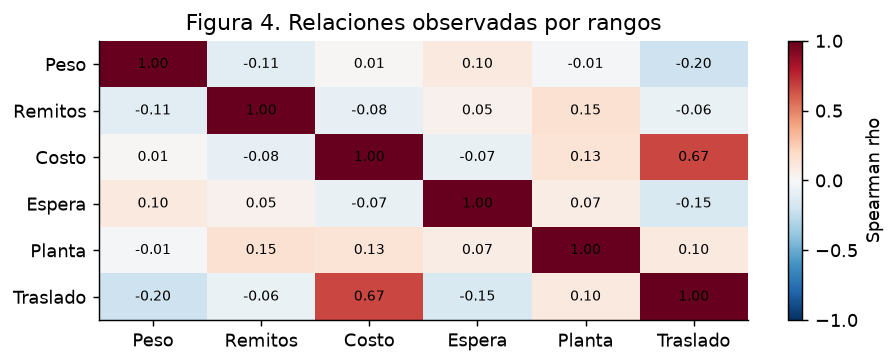

Control exploratorio dentro de ruta: {'n': 64594, 'rutas': 403, 'r_rangos_centrados': 0.20812330884169836, 'p_permutacion': 0.001, 'permutaciones': 999, 'rho_medianas_ruta': 0.007798124456282903, 'p_medianas_ruta': 0.8759838599299515}
Nota: p=0 en el cálculo asintótico significa subdesbordamiento numérico, no probabilidad nula.


In [6]:
# Reportar tamaño del efecto y distinguir asociación global de mezcla de rutas.
def holm(ps):
    ps=np.array(ps,dtype=float);orden=np.argsort(ps);aj=np.empty(len(ps))
    aj[orden]=np.minimum(1,np.maximum.accumulate(ps[orden]*(len(ps)-np.arange(len(ps)))))
    return aj
pruebas=[]
for col in ['Peso Total','#Remitos','Traslado_h']:
    z=b[[col,'Monto total']].dropna()
    rho,p=stats.spearmanr(z[col],z['Monto total'])
    pruebas.append({'Relación':col+' / costo','n':len(z),'rho':rho,'p':p})
pruebas=pd.DataFrame(pruebas);pruebas['p Holm']=holm(pruebas.p)
tabla(pruebas,'correlaciones.csv')
num=['Peso Total','#Remitos','Monto total','Espera_h','Planta_h','Traslado_h']
corr=b[num].corr(method='spearman')
fig,ax=plt.subplots(figsize=(7.2,2.9))
im=ax.imshow(corr,cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
labels=['Peso','Remitos','Costo','Espera','Planta','Traslado']
ax.set_xticks(range(6),labels);ax.set_yticks(range(6),labels)
for i in range(6):
    for j in range(6):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
ax.set_title('Figura 4. Relaciones observadas por rangos')
fig.colorbar(im,ax=ax,label='Spearman rho')
figura(fig,'figura_4_correlaciones.png')
frecuencias=b.Ruta.value_counts()
z=b[b.Ruta.isin(frecuencias[frecuencias>=30].index)].copy()
rx=z['Peso Total'].rank().to_numpy(copy=True);ry=z['Monto total'].rank().to_numpy(copy=True)
grupos=[a for a in z.groupby('Ruta',sort=True).indices.values()]
for idx in grupos:
    rx[idx]-=rx[idx].mean();ry[idx]-=ry[idx].mean()
den=np.linalg.norm(rx)*np.linalg.norm(ry)
r_dentro=float(np.dot(rx,ry)/den)
conteo=0
# La prueba conserva la ruta; no compara una ruta larga con otra corta.
for _ in range(999):
    yp=ry.copy()
    for idx in grupos:yp[idx]=rng.permutation(ry[idx])
    conteo+=abs(float(np.dot(rx,yp)/den))>=abs(r_dentro)
p_perm=(conteo+1)/1000
med=z.groupby('Ruta')[['Peso Total','Monto total']].median()
rho_med,p_med=stats.spearmanr(med['Peso Total'],med['Monto total'])
resumen['relaciones']=pruebas.to_dict('records')
resumen['dentro_ruta']={'n':len(z),'rutas':len(grupos),'r_rangos_centrados':r_dentro,
                      'p_permutacion':p_perm,'permutaciones':999,
                      'rho_medianas_ruta':float(rho_med),'p_medianas_ruta':float(p_med)}
print('Control exploratorio dentro de ruta:',resumen['dentro_ruta'])
print('Nota: p=0 en el cálculo asintótico significa subdesbordamiento numérico, no probabilidad nula.')

**Lectura de figura 4 y pruebas:** peso–costo rho=0.014, remitos–costo rho=-0.085 y traslado–costo rho=0.671. Los dos primeros efectos son pequeños aunque significativos. Dentro de 403 rutas (origen, región y localidad), la asociación de rangos peso–costo es 0.208 y p de permutación=0.001. Entre medianas de rutas rho=0.008, p=0.876. Las mezclas de rutas pueden ocultar estructura; las asociaciones no prueban ahorros ni causalidad.

## Fenómenos 3 
Pregunta guía de fenómeno 3: ¿podemos medir utilización real por tipo de camión, ruta y producto?

**Respuesta:** podemos describir peso, costo y mezcla de camiones por rutas observadas. No podemos calcular utilización real sin capacidad aplicable, producto y restricciones, ni atribuir espacio libre a desperdicio. La mediana de peso histórico no se usa como capacidad máxima.


In [7]:
# Fenómeno 3: comprobar qué línea base permiten construir los datos.
from IPython.display import display

# 1. Documentar la información disponible y sus limitaciones.
auditoria_f3 = pd.DataFrame([
    ["Tipo de camión", "Disponible", "Desc TpoTrn"],
    ["Ruta", "Disponible", "Origen, región y localidad"],
    ["Peso transportado", "Disponible", "Peso Total"],
    ["Unidad del peso", "Pendiente", "Requiere confirmación"],
    ["Capacidad aplicable del camión", "No disponible", "Requiere catálogo"],
    ["Producto transportado", "No disponible", "Requiere identificación"],
    ["Dimensión que limita la carga", "No determinable",
     "Faltan capacidades y restricciones"]
], columns=["Información necesaria", "Estado", "Evidencia"])

display(auditoria_f3)

# La utilización por peso sería:
# 100 * peso transportado / capacidad útil aplicable.
# Ambos valores deben estar en la misma unidad.
# No usamos el máximo ni la mediana histórica como capacidad.

# 2. Construir una línea base descriptiva por ruta y tipo de camión.
columnas_ruta = ["Planta Origen", "D_REGION", "ZONA_LOCALIDAD"]
columnas_grupo = columnas_ruta + ["Desc TpoTrn"]

linea_base = (
    b.groupby(columnas_grupo, dropna=False)
    .agg(
        viajes=("Viaje", "size"),
        peso_mediano=("Peso Total", "median"),
        peso_varianza=("Peso Total", "var"),
        peso_p25=("Peso Total", lambda x: x.quantile(0.25)),
        peso_p75=("Peso Total", lambda x: x.quantile(0.75)),
        costo_mediano_MXN=("Monto total", "median"),
        pesos_para_revisar=(
            "Peso Total",
            lambda x: int((x > 100000).sum())
        )
    )
    .reset_index()
)

# El umbral de 100,000 solo señala pesos para revisión.
# No representa un límite de capacidad ni un límite legal.

# Varianza muestral del peso (ddof=1), en unidades originales al cuadrado.
# Los grupos con un solo peso valido tienen varianza indefinida (NaN).

# 3. Calcular la participación de cada tipo dentro de su ruta.
linea_base["viajes_en_ruta"] = (
    linea_base.groupby(columnas_ruta, dropna=False)["viajes"]
    .transform("sum")
)

linea_base["participacion_en_ruta_pct"] = (
    100 * linea_base["viajes"] / linea_base["viajes_en_ruta"]
)

linea_base = linea_base.sort_values(
    "viajes", ascending=False
).reset_index(drop=True)

print("Combinaciones de ruta y tipo:", len(linea_base))
print("Viajes representados:", linea_base["viajes"].sum())
print("Las siguientes son las 12 combinaciones con más viajes:")

display(linea_base.head(12).round(2))

# Guardar toda la tabla, no únicamente las primeras 12 filas.
linea_base.to_csv(
    OUT / "fenomeno_3_linea_base.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Conclusión: se puede construir una línea base descriptiva "
    "por ruta y tipo de camión. La utilización real por producto "
    "no puede calcularse con la información actual."
)

,Información necesaria,Estado,Evidencia
0,Tipo de camión,Disponible,Desc TpoTrn
1,Ruta,Disponible,"Origen, región y localidad"
2,Peso transportado,Disponible,Peso Total
3,Unidad del peso,Pendiente,Requiere confirmación
4,Capacidad aplicable del camión,No disponible,Requiere catálogo
5,Producto transportado,No disponible,Requiere identificación
6,Dimensión que limita la carga,No determinable,Faltan capacidades y restricciones


Combinaciones de ruta y tipo: 3704
Viajes representados: 76070
Las siguientes son las 12 combinaciones con más viajes:


,Planta Origen,D_REGION,ZONA_LOCALIDAD,Desc TpoTrn,viajes,peso_mediano,peso_varianza,peso_p25,peso_p75,costo_mediano_MXN,pesos_para_revisar,viajes_en_ruta,participacion_en_ruta_pct
0,PSQ,COAHUILA,CASTAÑOS,3_EJES,2558,26975.0,7541844.62,26160.00,27220.00,12050.00,0,2564,99.77
1,PSQ,COAHUILA,RAMOS ARIZPE,3_EJES,1961,31744.0,29127393.37,26408.00,35215.00,9900.00,0,2472,79.33
2,CSCA,MEXICO,TULTITLAN,2_EJES,1517,24872.0,2902994.59,23533.00,25427.00,38400.00,0,1523,99.61
3,PSQ,SAN LUIS POTOSI,SAN LUIS POTOSI,3_EJES,1147,31700.0,21396639.01,26715.00,34945.00,25926.58,0,1575,72.83
4,GUE,COAHUILA,CIUDAD FRONTERA,3_EJES,1118,36125.0,33715874.45,34318.00,36840.00,11400.00,0,1123,99.55
5,PSQ,TAMAULIPAS,ALTAMIRA,2_EJES,980,22985.0,2016022.70,21440.00,23967.75,14359.14,0,1717,57.08
6,CHU,COAHUILA,RAMOS ARIZPE,3_EJES,975,29748.0,35474082.24,22649.00,32971.00,9900.00,0,1064,91.64
7,GUE,COAHUILA,RAMOS ARIZPE,3_EJES,944,30872.5,43104299.83,22488.75,34055.00,9900.00,0,980,96.33
8,GUE,TAMAULIPAS,NUEVO LAREDO,3_EJES,934,33075.0,7547894.12,31139.00,34347.00,15653.34,0,975,95.79
9,LPU,SAN LUIS POTOSI,SAN LUIS POTOSI,3_EJES,883,35220.0,834196.81,34743.00,35222.00,31029.78,0,1077,81.99


Conclusión: se puede construir una línea base descriptiva por ruta y tipo de camión. La utilización real por producto no puede calcularse con la información actual.


PCA Fenómeno 3: 51,925 viajes completos de 76,070 (68.3%).
Varianza explicada por CP1 y CP2: 24.2% y 23.0%; acumulada: 47.1%.
El PCA describe perfiles; no mide utilización ni capacidad del camión.
Cargas de las variables en los componentes (el signo es arbitrario):


,Variable,CP1,CP2
0,Peso Total,0.023,-0.485
1,#Remitos,0.636,0.068
2,Espera_h,0.465,-0.423
3,Planta_h,0.614,0.302
4,Traslado_h,-0.030,0.700


Resumen descriptivo por tipo de camión:


,Desc TpoTrn,viajes,CP1_mediana,CP2_mediana,peso_mediano,remitos_medianos
0,3_EJES,36047,-0.22,-0.39,32208.0,1.0
1,2_EJES,13421,-0.02,1.06,25014.0,1.0
2,PORTACINTAS,1488,-0.03,-0.53,31587.5,1.0
3,MENORES,444,0.02,1.45,9880.0,2.0
4,CAMIONETA,317,-0.86,2.80,2820.0,1.0
5,DOBLE_PISO,113,0.13,-0.97,29159.0,1.0
6,CAJA_SECA,95,-0.71,0.01,24000.0,1.0


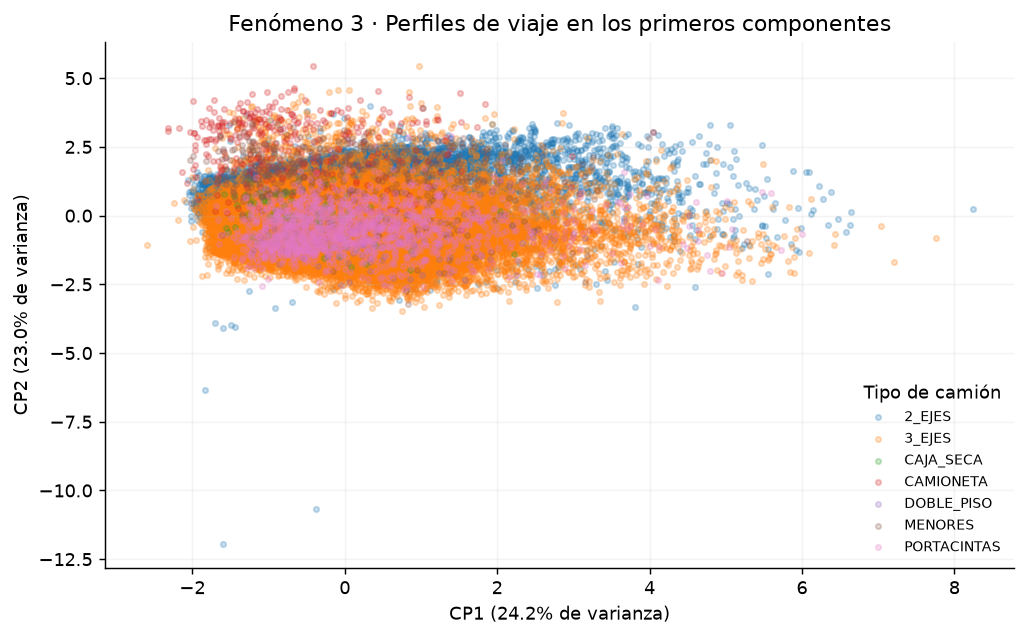

In [8]:
# Fenómeno 3 · PCA exploratorio de perfiles por tipo de camión.
# Excluimos costo: el foco es carga y operación, no predecir costos.
variables_pca_f3 = ["Peso Total", "#Remitos", "Espera_h", "Planta_h", "Traslado_h"]
columnas_contexto_f3 = ["Viaje", "Desc TpoTrn", "Planta Origen", "D_REGION", "ZONA_LOCALIDAD"]
pca_f3 = b[columnas_contexto_f3 + variables_pca_f3].dropna().copy()

# Log1p reduce el efecto de las colas largas; la estandarización iguala escalas.
X_f3 = np.log1p(pca_f3[variables_pca_f3].astype(float))
X_f3 = StandardScaler().fit_transform(X_f3)
modelo_pca_f3 = PCA(n_components=2, svd_solver="full", random_state=SEED)
coordenadas_f3 = modelo_pca_f3.fit_transform(X_f3)
pca_f3["CP1"] = coordenadas_f3[:, 0]
pca_f3["CP2"] = coordenadas_f3[:, 1]
pca_f3["Desc TpoTrn"] = pca_f3["Desc TpoTrn"].fillna("Sin dato").astype(str)

varianza_f3 = modelo_pca_f3.explained_variance_ratio_
print(f"PCA Fenómeno 3: {len(pca_f3):,} viajes completos de {len(b):,} ({len(pca_f3) / len(b):.1%}).")
print(f"Varianza explicada por CP1 y CP2: {varianza_f3[0]:.1%} y {varianza_f3[1]:.1%}; acumulada: {varianza_f3.sum():.1%}.")
print("El PCA describe perfiles; no mide utilización ni capacidad del camión.")

cargas_pca_f3 = pd.DataFrame(
    modelo_pca_f3.components_.T,
    index=variables_pca_f3,
    columns=["CP1", "CP2"]
).rename_axis("Variable").reset_index()
resumen_pca_f3 = (
    pca_f3.groupby("Desc TpoTrn", dropna=False)
    .agg(viajes=("Viaje", "size"), CP1_mediana=("CP1", "median"),
         CP2_mediana=("CP2", "median"), peso_mediano=("Peso Total", "median"),
         remitos_medianos=("#Remitos", "median"))
    .sort_values("viajes", ascending=False)
    .reset_index()
)
print("Cargas de las variables en los componentes (el signo es arbitrario):")
display(cargas_pca_f3.round(3))
print("Resumen descriptivo por tipo de camión:")
display(resumen_pca_f3.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
for tipo, grupo in pca_f3.groupby("Desc TpoTrn", dropna=False, sort=True):
    ax.scatter(grupo["CP1"], grupo["CP2"], s=9, alpha=0.25, label=tipo, rasterized=True)
ax.set_xlabel(f"CP1 ({varianza_f3[0]:.1%} de varianza)")
ax.set_ylabel(f"CP2 ({varianza_f3[1]:.1%} de varianza)")
ax.set_title("Fenómeno 3 · Perfiles de viaje en los primeros componentes")
ax.legend(title="Tipo de camión", frameon=False, fontsize=8)
ax.grid(alpha=0.15)
figura(fig, "fenomeno_3_pca_tipos_camion.png")

pca_f3.to_csv(OUT / "fenomeno_3_pca_proyecciones.csv", index=False, encoding="utf-8-sig")
resumen_pca_f3.to_csv(OUT / "fenomeno_3_pca_resumen_tipo.csv", index=False, encoding="utf-8-sig")

### Línea base por tipo de camión: mediana y varianza
La siguiente celda calcula la varianza muestral del peso por tipo de camión y la muestra junto a la gráfica.

,viajes,peso_mediano,peso_varianza
Desc TpoTrn,,,
3_EJES,50698,32149.0,3.331215e+07
PORTACINTAS,2157,31524.0,2.519277e+07
DOBLE_PISO,170,29241.5,7.781686e+06
0,1,25538.0,NaN
2_EJES,19344,24989.0,3.661701e+11
CAJA_SECA,290,24000.0,1.176639e+07
MENORES,2359,12735.0,1.739750e+07
CAMIONETA,1051,2740.0,7.164972e+05


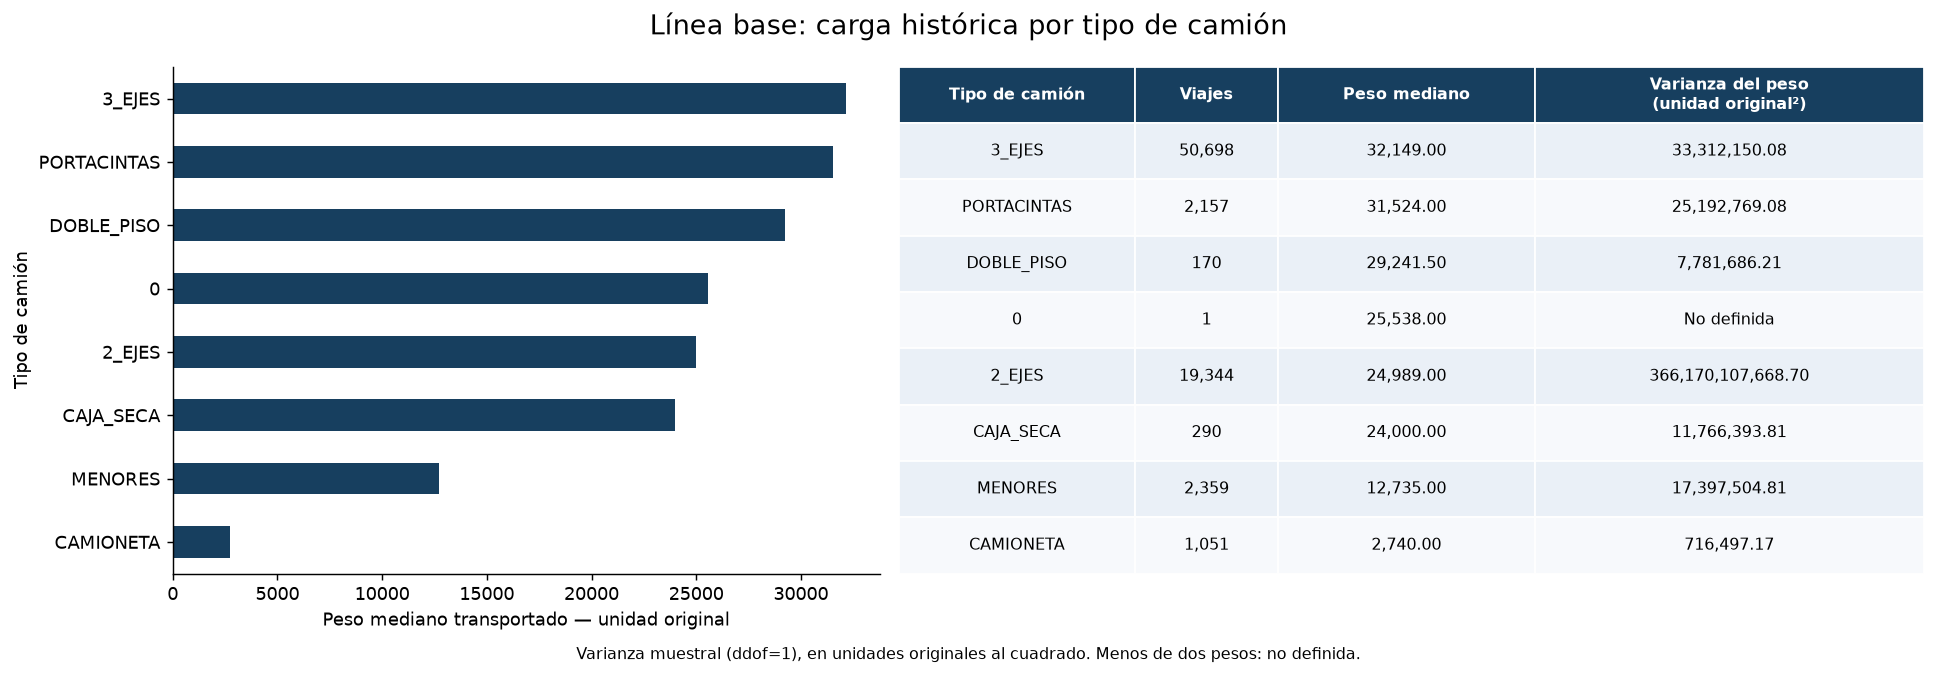

In [9]:
# Calcular la mediana y la varianza directamente con los pesos de cada tipo.
from IPython.display import display

resumen_por_tipo = (
    b.groupby("Desc TpoTrn", dropna=False)["Peso Total"]
    .agg(viajes="count", peso_mediano="median", peso_varianza="var")
    .sort_values("peso_mediano", ascending=False)
)

# La varianza muestral usa ddof=1; un solo viaje produce NaN.
display(resumen_por_tipo.round(2))
resumen_por_tipo.to_csv(
    OUT / "fenomeno_3_resumen_por_tipo.csv", encoding="utf-8-sig"
)

fig, (ax, ax_tabla) = plt.subplots(
    1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.45]}
)
resumen_por_tipo["peso_mediano"].iloc[::-1].plot.barh(ax=ax, color="#173F5F")
ax.set_xlabel("Peso mediano transportado \u2014 unidad original")
ax.set_ylabel("Tipo de cami\u00f3n")
ax_tabla.axis("off")

filas = [
    [str(tipo), f"{int(fila.viajes):,}", f"{fila.peso_mediano:,.2f}",
     f"{fila.peso_varianza:,.2f}" if pd.notna(fila.peso_varianza) else "No definida"]
    for tipo, fila in resumen_por_tipo.iterrows()
]
tabla_tipo = ax_tabla.table(
    cellText=filas,
    colLabels=["Tipo de cami\u00f3n", "Viajes", "Peso mediano",
               "Varianza del peso\n(unidad original\u00b2)"],
    cellLoc="center", colWidths=[0.23, 0.14, 0.25, 0.38], bbox=[0, 0, 1, 1]
)
tabla_tipo.auto_set_font_size(False)
tabla_tipo.set_fontsize(9)
for (fila, columna), celda in tabla_tipo.get_celld().items():
    celda.set_edgecolor("white")
    celda.set_facecolor("#173F5F" if fila == 0 else
                       ("#EAF0F7" if fila % 2 else "#F7F9FC"))
    if fila == 0:
        celda.set_text_props(color="white", weight="bold")
fig.suptitle("L\u00ednea base: carga hist\u00f3rica por tipo de cami\u00f3n", fontsize=15)
fig.text(0.5, -0.015,
         "Varianza muestral (ddof=1), en unidades originales al cuadrado. Menos de dos pesos: no definida.",
         ha="center", fontsize=9)
figura(fig, "fenomeno_3_peso_por_tipo.png")


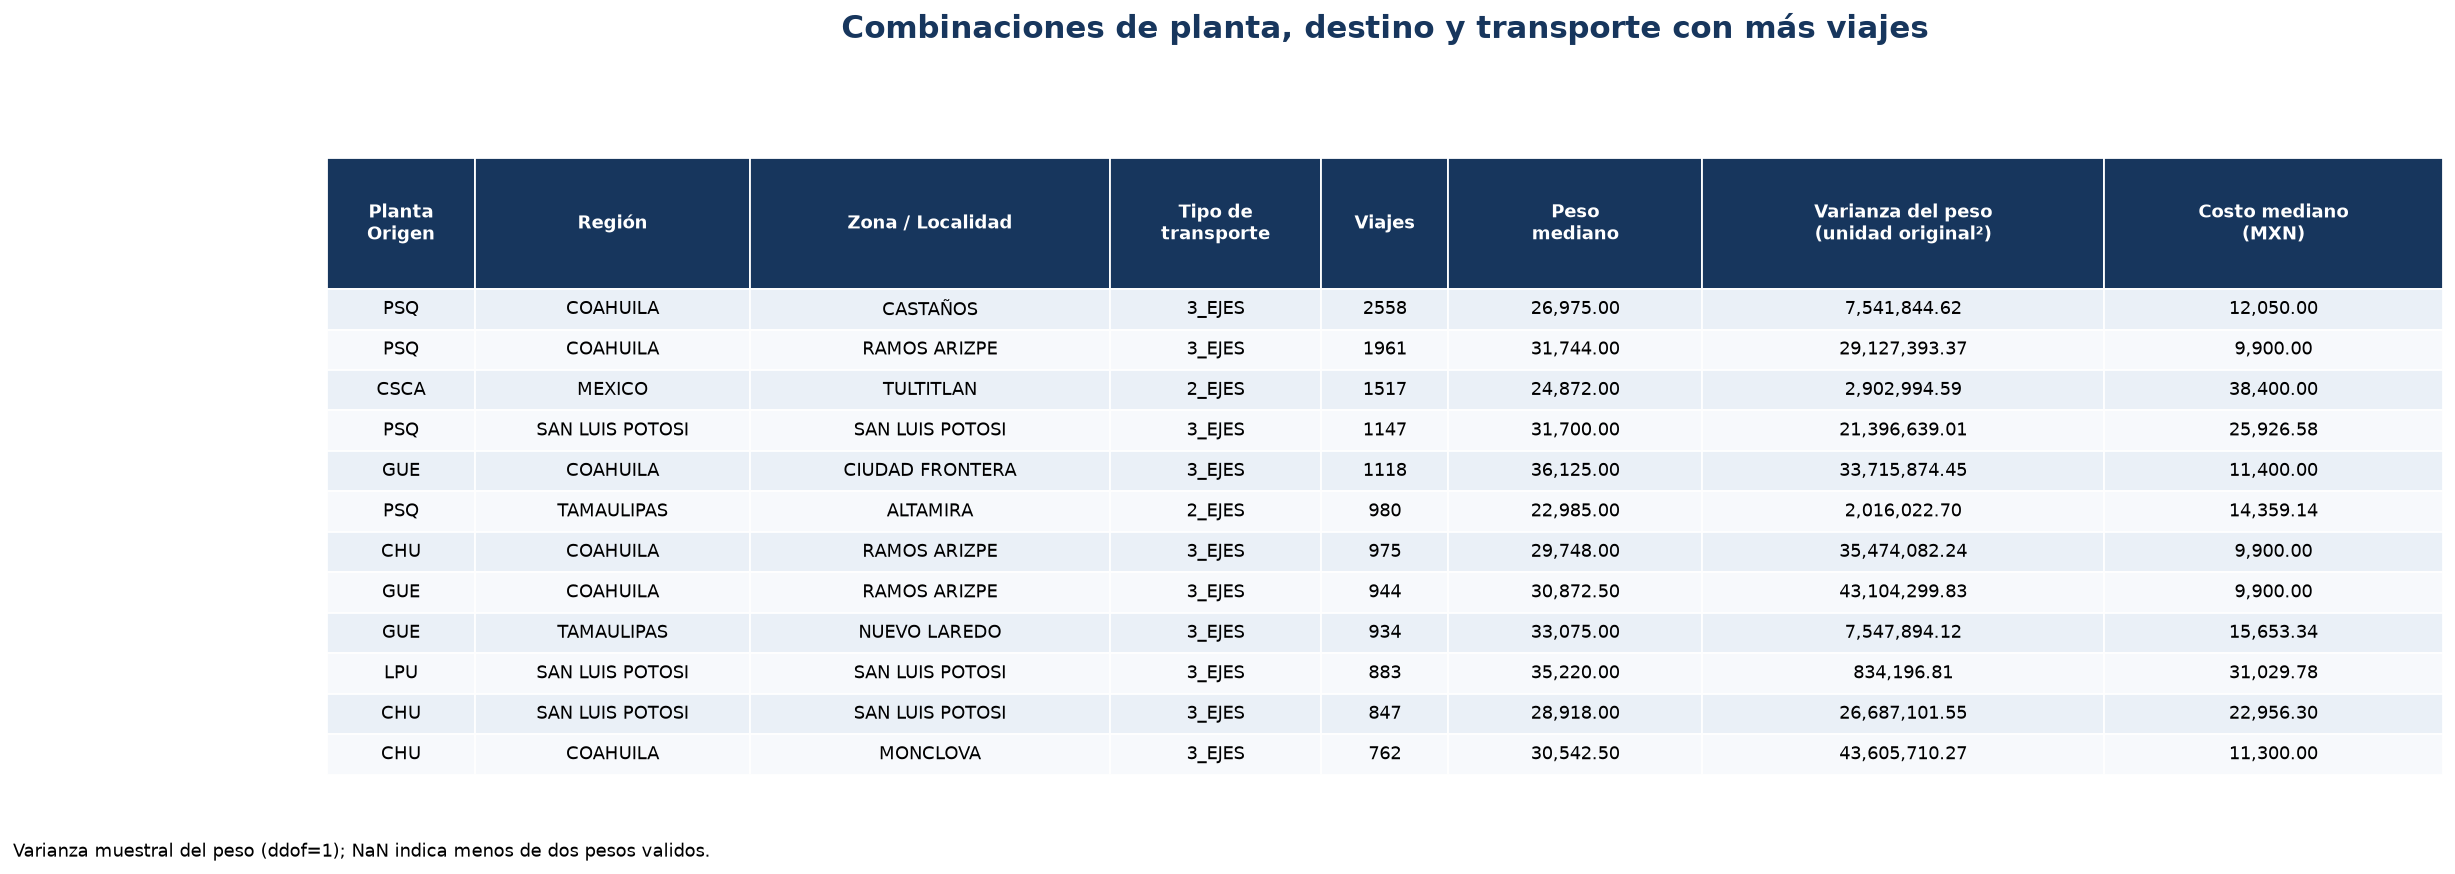

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Usar la linea base calculada en la celda anterior, con su varianza.
columnas_tabla = [
    "Planta Origen", "D_REGION", "ZONA_LOCALIDAD", "Desc TpoTrn",
    "viajes", "peso_mediano", "peso_varianza", "costo_mediano_MXN"
]
df = linea_base.head(12).loc[:, columnas_tabla].copy()

# Formato para visualizar los números
for columna in ["peso_mediano", "peso_varianza", "costo_mediano_MXN"]:
    df[columna] = df[columna].map(lambda valor: f"{valor:,.2f}")

encabezados = [
    "Planta\nOrigen", "Región", "Zona / Localidad", "Tipo de\ntransporte",
    "Viajes", "Peso\nmediano", "Varianza del peso\n(unidad original²)", "Costo mediano\n(MXN)"
]

fig, ax = plt.subplots(figsize=(21, 7))
ax.axis("off")

tabla = ax.table(
    cellText=df.values,
    colLabels=encabezados,
    cellLoc="center",
    colWidths=[0.07, 0.13, 0.17, 0.10, 0.06, 0.12, 0.19, 0.16],
    bbox=[0, 0, 1, 0.88]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(10)

for (fila, columna), celda in tabla.get_celld().items():
    celda.set_edgecolor("#FFFFFF")
    celda.set_linewidth(1)

    if fila == 0:
        celda.set_facecolor("#17365D")
        celda.set_text_props(color="white", weight="bold")
        celda.set_height(0.10)
    else:
        celda.set_facecolor("#EAF0F7" if fila % 2 else "#F7F9FC")

ax.set_title(
    "Combinaciones de planta, destino y transporte con más viajes",
    fontsize=17,
    fontweight="bold",
    color="#17365D",
    pad=20
)

fig.text(0.01, 0.02, "Varianza muestral del peso (ddof=1); NaN indica menos de dos pesos validos.", fontsize=10)
fig.savefig(OUT.parent / "tabla_linea_base.png", dpi=300, bbox_inches="tight")
plt.show()

## Análisis 3
**Lectura de figura 5:** los dos primeros componentes explican 47.13% de la variabilidad sin costo y 48.71% con costo. Cuatro componentes superan el 80% en ambos modelos. La estructura no se resume suficientemente en dos dimensiones; los porcentajes corresponden a conjuntos de variables distintos y no representan una mejora predictiva.

**Lectura de figura 6:** sin costo, CP1 combina principalmente remitos, permanencia en planta y espera; CP2 destaca traslado y contrasta con peso y espera. Con costo, CP1 agrupa principalmente traslado y monto total, mientras CP2 reúne remitos, permanencia y espera. Esta estructura describe variación conjunta, no efectos causales ni ahorros por reasignación.

**Respuesta al fenómeno 3:** podemos describir la carga histórica, el costo y la mezcla de camiones por ruta y tipo de transporte. La combinación PSQ–Castaños–3_EJES concentra 2,558 viajes, con peso mediano de 26,975 en la unidad original y costo mediano de MXN 12,050. No podemos medir utilización real por producto: faltan capacidad útil aplicable, identificación del producto y restricciones, además de confirmar la unidad del peso. Las diferencias de carga observadas no demuestran subutilización; la mediana histórica no equivale a capacidad máxima.